temp sandbox notebook

In [2]:
# from train.py
import numpy as np
from omegaconf import OmegaConf
import pathlib

from models import *
from tasks import *
import config
import trainer_masked
import utils

In [1]:
# from train.py
args = config.load_train_config()

print("Experiment configuration:")
print(OmegaConf.to_yaml(args, resolve=True, sort_keys=True))

utils.set_random_seeds(args.seed)

pathlib.Path(args.path).mkdir(parents=True, exist_ok=True)

ConfigAttributeError: Missing key config
    full_key: config
    object_type=dict

In [ ]:
# example args for train.py
#config=spatial_navigation/noisy_unbiased seed=0

In [69]:
# from train.py
task = spatial_navigation.SpatialNavigation(device='cpu')
train_data_generator = task.get_generator()
# from trainer.py
train_data = train_data_generator
for batch in train_data:
    break

In [70]:
print(batch['init_pos'].shape)
print(batch['data'].shape)

torch.Size([200, 1, 2])
torch.Size([200, 100, 2])


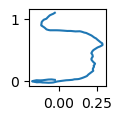

In [71]:
# verify that dim 1 of batch['data'] is time, and that each entry is velocity
import matplotlib.pyplot as plt
traj = batch['data'][0].cumsum(0)
plt.figure(figsize=(1,1))
plt.plot(traj[:,0], traj[:,1]);

In [72]:
unmask_every = 3
T = batch['data'].shape[1]
batch['data'][:, np.arange(T) % unmask_every != 0] = 0
batch['data'].sum(0)

tensor([[-0.1186, -0.1648],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [-0.1101, -0.0130],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.0740, -0.2390],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [-0.0430, -0.0901],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.2043,  0.0773],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.2661,  0.0027],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.3920, -0.1436],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.4356,  0.0520],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.2228, -0.2892],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.4966, -0.2465],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.2826, -0.1469],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000],
        [ 0.1499,  0.1171],
        [ 0.0000,  0.0000],
        [ 0.0000,  0